# Projeto de Aprendizado de Máquina - Marketing Bancário

Neste projeto, vamos trabalhar com uma base de dados de um banco português para tentar prever se os clientes vão aderir ou não a um depósito a prazo.

Para isso, primeiro vamos analisar os dados e fazer a preparação da base. Depois, vamos treinar alguns modelos de aprendizado de máquina e comparar os resultados para ver como cada um se saiu.

Os modelos que vamos utilizar são:

* k-Vizinhos Mais Próximos (k-NN);
* Naive Bayes;
* Regressão Logística.

Também vamos trabalhar com dois cenários diferentes:

* **Cenário principal:** utilizando apenas as informações que já estavam disponíveis antes da ligação para o cliente;
* **Cenário completo:** utilizando todas as informações disponíveis na base.

A partir disso, vamos comparar os resultados dos modelos nos dois cenários e analisar as diferenças encontradas.


In [ ]:
# Importação das bibliotecas utilizadas no projeto

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [ ]:
# Importando a ferramenta para enviar o arquivo ao Google Colab

from google.colab import files

uploaded = files.upload()

Saving bank_marketing_completo.csv to bank_marketing_completo.csv


In [ ]:
# Carregando a base de dados

df = pd.read_csv("bank_marketing_completo.csv")

print("Base carregada com sucesso!")

Base carregada com sucesso!


In [ ]:
# Verificando a quantidade de linhas e colunas

print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

Quantidade de linhas: 41188
Quantidade de colunas: 21


In [ ]:
# Visualizando as primeiras linhas da base

df.head()

,idade,profissao,estado_civil,escolaridade,inadimplente,financiamento_imobiliario,emprestimo_pessoal,meio_contato,mes,dia_semana,...,contatos_campanha_atual,dias_desde_ultimo_contato,contatos_anteriores,resultado_campanha_anterior,taxa_variacao_emprego,indice_precos_consumidor,indice_confianca_consumidor,euribor_3m,numero_empregados,aderiu
0,56,empregado_domestico,casado,fundamental_4anos,nao,nao,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
1,57,servicos,casado,ensino_medio,desconhecido,nao,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
2,37,servicos,casado,ensino_medio,nao,sim,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
3,40,administrativo,casado,fundamental_6anos,nao,nao,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
4,56,servicos,casado,ensino_medio,nao,nao,sim,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao


In [ ]:
# Verificando os tipos das variáveis e informações gerais da base

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   idade                        41188 non-null  int64  
 1   profissao                    41188 non-null  object 
 2   estado_civil                 41188 non-null  object 
 3   escolaridade                 41188 non-null  object 
 4   inadimplente                 41188 non-null  object 
 5   financiamento_imobiliario    41188 non-null  object 
 6   emprestimo_pessoal           41188 non-null  object 
 7   meio_contato                 41188 non-null  object 
 8   mes                          41188 non-null  object 
 9   dia_semana                   41188 non-null  object 
 10  duracao_ligacao_seg          41188 non-null  int64  
 11  contatos_campanha_atual      41188 non-null  int64  
 12  dias_desde_ultimo_contato    41188 non-null  int64  
 13  contatos_anterio

In [ ]:
# Verificando valores ausentes

print("Valores ausentes por coluna:")
print(df.isnull().sum())

Valores ausentes por coluna:
idade                          0
profissao                      0
estado_civil                   0
escolaridade                   0
inadimplente                   0
financiamento_imobiliario      0
emprestimo_pessoal             0
meio_contato                   0
mes                            0
dia_semana                     0
duracao_ligacao_seg            0
contatos_campanha_atual        0
dias_desde_ultimo_contato      0
contatos_anteriores            0
resultado_campanha_anterior    0
taxa_variacao_emprego          0
indice_precos_consumidor       0
indice_confianca_consumidor    0
euribor_3m                     0
numero_empregados              0
aderiu                         0
dtype: int64


In [ ]:
# Visualizando estatísticas das variáveis numéricas

df.describe()

,idade,duracao_ligacao_seg,contatos_campanha_atual,dias_desde_ultimo_contato,contatos_anteriores,taxa_variacao_emprego,indice_precos_consumidor,indice_confianca_consumidor,euribor_3m,numero_empregados
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [ ]:
# Verificando a quantidade de clientes em cada classe

print(df["aderiu"].value_counts())

print("\nPercentual de cada classe:")
print(df["aderiu"].value_counts(normalize=True) * 100)

aderiu
nao    36548
sim     4640
Name: count, dtype: int64

Percentual de cada classe:
aderiu
nao    88.734583
sim    11.265417
Name: proportion, dtype: float64


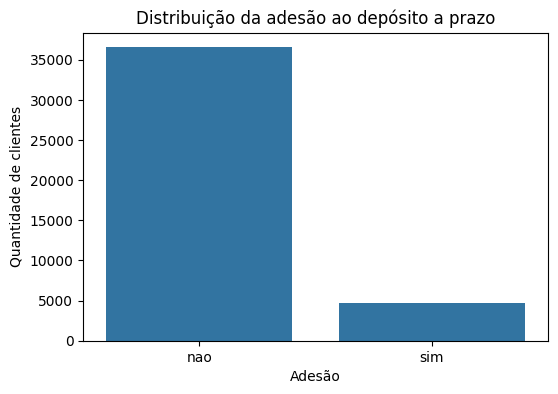

In [ ]:
# Visualizando a distribuição da variável alvo

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="aderiu")

plt.title("Distribuição da adesão ao depósito a prazo")
plt.xlabel("Adesão")
plt.ylabel("Quantidade de clientes")

plt.show()

In [ ]:
# Verificando a quantidade de registros classificados como "desconhecido"

colunas_categoricas = df.select_dtypes(include="object").columns

for coluna in colunas_categoricas:
    quantidade = (df[coluna] == "desconhecido").sum()

    if quantidade > 0:
        print(coluna, ":", quantidade)

profissao : 330
estado_civil : 80
escolaridade : 1731
inadimplente : 8597
financiamento_imobiliario : 990
emprestimo_pessoal : 990


In [ ]:
# Verificando o significado do valor 999 em dias_desde_ultimo_contato

print("Quantidade de registros com 999:")
print((df["dias_desde_ultimo_contato"] == 999).sum())

print("\nQuantidade de registros diferentes de 999:")
print((df["dias_desde_ultimo_contato"] != 999).sum())

Quantidade de registros com 999:
39673

Quantidade de registros diferentes de 999:
1515


In [ ]:
# Verificando registros duplicados

duplicados = df.duplicated().sum()

print("Quantidade de registros duplicados:", duplicados)

Quantidade de registros duplicados: 12


In [ ]:
# Removendo registros duplicados

df = df.drop_duplicates().copy()

print("Nova quantidade de linhas:", df.shape[0])

Nova quantidade de linhas: 41176


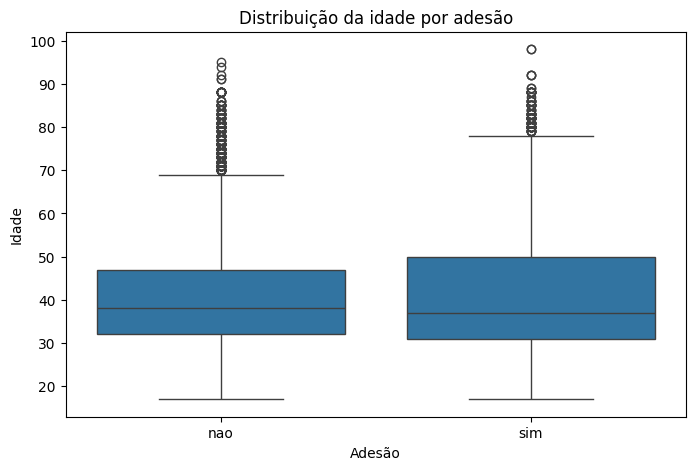

In [ ]:
# Distribuição da idade de acordo com a adesão

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="aderiu", y="idade")

plt.title("Distribuição da idade por adesão")
plt.xlabel("Adesão")
plt.ylabel("Idade")

plt.show()

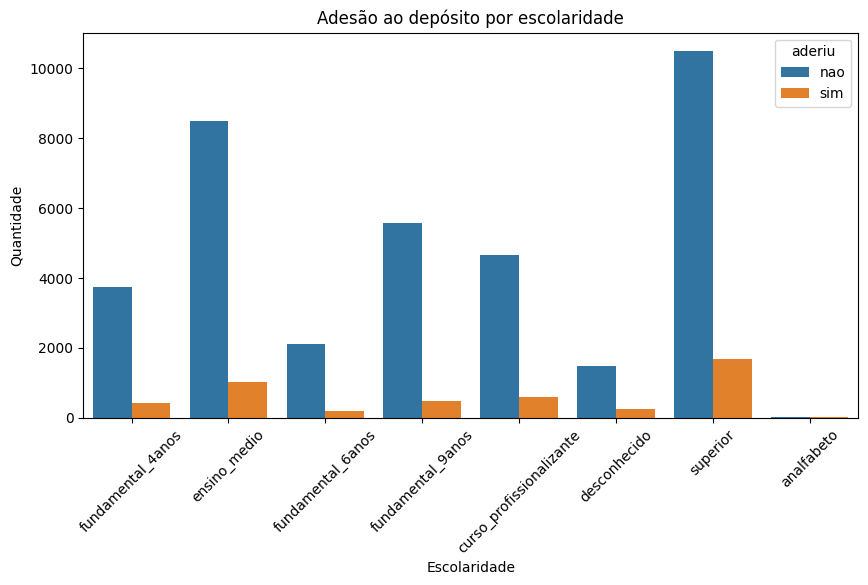

In [ ]:
# Relação entre escolaridade e adesão

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="escolaridade",
    hue="aderiu"
)

plt.title("Adesão ao depósito por escolaridade")
plt.xlabel("Escolaridade")
plt.ylabel("Quantidade")
plt.xticks(rotation=45)

plt.show()

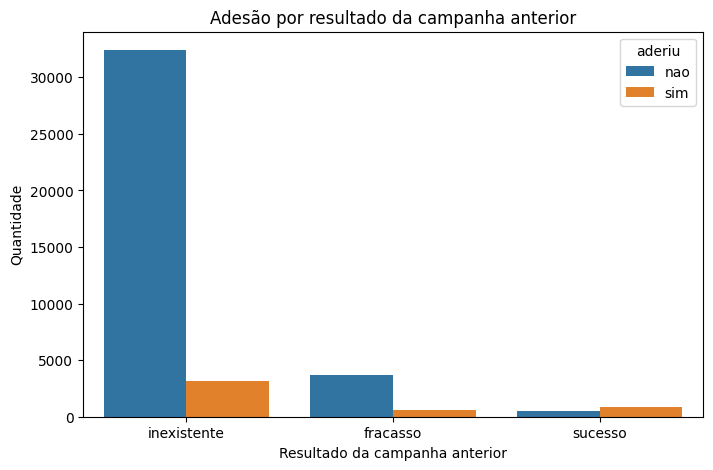

In [ ]:
# Relação entre o resultado da campanha anterior e a adesão

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="resultado_campanha_anterior",
    hue="aderiu"
)

plt.title("Adesão por resultado da campanha anterior")
plt.xlabel("Resultado da campanha anterior")
plt.ylabel("Quantidade")

plt.show()

In [ ]:
# Calculando a taxa de adesão por resultado da campanha anterior

taxa_adesao = pd.crosstab(
    df["resultado_campanha_anterior"],
    df["aderiu"],
    normalize="index"
) * 100

print(taxa_adesao)

aderiu                             nao        sim
resultado_campanha_anterior                      
fracasso                     85.771402  14.228598
inexistente                  91.167618   8.832382
sucesso                      34.887109  65.112891


In [ ]:
# Comparando a duração da ligação entre clientes que aderiram e não aderiram

print(
    df.groupby("aderiu")["duracao_ligacao_seg"].mean()
)

aderiu
nao    220.868079
sim    553.256090
Name: duracao_ligacao_seg, dtype: float64


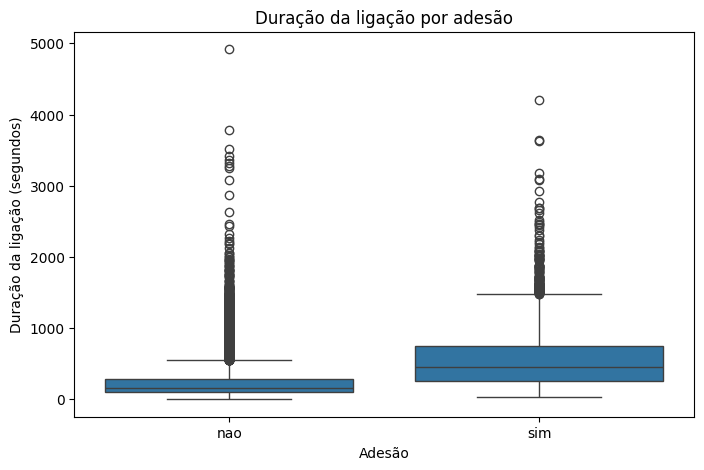

In [ ]:
# Distribuição da duração da ligação por adesão

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="aderiu",
    y="duracao_ligacao_seg"
)

plt.title("Duração da ligação por adesão")
plt.xlabel("Adesão")
plt.ylabel("Duração da ligação (segundos)")

plt.show()

In [ ]:
# Criando uma variável para indicar clientes que nunca foram contatados anteriormente

df["nunca_contatado"] = (
    df["dias_desde_ultimo_contato"] == 999
).astype(int)

print(df["nunca_contatado"].value_counts())

nunca_contatado
1    39661
0     1515
Name: count, dtype: int64


In [ ]:
# Transformando o código 999 em valor ausente para tratamento posterior

df["dias_desde_ultimo_contato"] = df["dias_desde_ultimo_contato"].replace(999, np.nan)

print(df["dias_desde_ultimo_contato"].isnull().sum())

39661


In [ ]:
# Listando todas as colunas da base

for coluna in df.columns:
    print(coluna)

idade
profissao
estado_civil
escolaridade
inadimplente
financiamento_imobiliario
emprestimo_pessoal
meio_contato
mes
dia_semana
duracao_ligacao_seg
contatos_campanha_atual
dias_desde_ultimo_contato
contatos_anteriores
resultado_campanha_anterior
taxa_variacao_emprego
indice_precos_consumidor
indice_confianca_consumidor
euribor_3m
numero_empregados
aderiu
nunca_contatado


In [ ]:
# Separando as variáveis dos dois cenários

target = "aderiu"

colunas_excluir_principal = [
    "aderiu",
    "duracao_ligacao_seg"
]

colunas_excluir_completo = [
    "aderiu"
]

X_principal = df.drop(columns=colunas_excluir_principal)
X_completo = df.drop(columns=colunas_excluir_completo)

y = df[target]

print("Colunas do cenário principal:", X_principal.shape[1])
print("Colunas do cenário completo:", X_completo.shape[1])

Colunas do cenário principal: 20
Colunas do cenário completo: 21


In [ ]:
# Transformando a variável alvo em valores numéricos

y = y.map({
    "nao": 0,
    "sim": 1
})

print(y.value_counts())

aderiu
0    36537
1     4639
Name: count, dtype: int64


In [ ]:
# Separando os dados em treino e teste

X_train_principal, X_test_principal, y_train, y_test = train_test_split(
    X_principal,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_train_completo, X_test_completo, _, _ = train_test_split(
    X_completo,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Treino:", X_train_principal.shape)
print("Teste:", X_test_principal.shape)

Treino: (28823, 20)
Teste: (12353, 20)


In [ ]:
# Identificando as variáveis numéricas e categóricas

colunas_numericas = X_train_principal.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

colunas_categoricas = X_train_principal.select_dtypes(
    include=["object"]
).columns.tolist()

print("Variáveis numéricas:")
print(colunas_numericas)

print("\nVariáveis categóricas:")
print(colunas_categoricas)

Variáveis numéricas:
['idade', 'contatos_campanha_atual', 'dias_desde_ultimo_contato', 'contatos_anteriores', 'taxa_variacao_emprego', 'indice_precos_consumidor', 'indice_confianca_consumidor', 'euribor_3m', 'numero_empregados', 'nunca_contatado']

Variáveis categóricas:
['profissao', 'estado_civil', 'escolaridade', 'inadimplente', 'financiamento_imobiliario', 'emprestimo_pessoal', 'meio_contato', 'mes', 'dia_semana', 'resultado_campanha_anterior']


In [ ]:
# Criando a preparação das variáveis numéricas e categóricas

preprocessamento = ColumnTransformer(
    transformers=[
        (
            "numericas",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            colunas_categoricas
        )
    ]
)

print("Pré-processamento criado com sucesso!")

Pré-processamento criado com sucesso!


In [ ]:
# Criando o pipeline do KNN

pipeline_knn = Pipeline([
    ("preprocessamento", preprocessamento),
    ("modelo", KNeighborsClassifier())
])

In [ ]:
# Testando diferentes valores de k por validação cruzada

parametros_knn = {
    "modelo__n_neighbors": [3, 5, 7, 9, 11]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_knn = GridSearchCV(
    pipeline_knn,
    parametros_knn,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_knn.fit(X_train_principal, y_train)

print("Melhor k:", grid_knn.best_params_)
print("Melhor F1 na validação cruzada:", grid_knn.best_score_)

Melhor k: {'modelo__n_neighbors': 5}
Melhor F1 na validação cruzada: 0.3792504573792545


In [ ]:
# Criando o pipeline da Regressão Logística

pipeline_logistica = Pipeline([
    ("preprocessamento", preprocessamento),
    ("modelo", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

In [ ]:
# Testando diferentes valores de C por validação cruzada

parametros_logistica = {
    "modelo__C": [0.01, 0.1, 1, 10, 100]
}

grid_logistica = GridSearchCV(
    pipeline_logistica,
    parametros_logistica,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_logistica.fit(X_train_principal, y_train)

print("Melhor C:", grid_logistica.best_params_)
print("Melhor F1 na validação cruzada:", grid_logistica.best_score_)

Melhor C: {'modelo__C': 100}
Melhor F1 na validação cruzada: 0.34504125146903775


In [ ]:
# Criando o pipeline do Naive Bayes

pipeline_nb = Pipeline([
    ("preprocessamento", preprocessamento),
    ("modelo", GaussianNB())
])

pipeline_nb.fit(X_train_principal, y_train)

print("Naive Bayes treinado com sucesso!")

Naive Bayes treinado com sucesso!


In [ ]:
# Fazendo as previsões no conjunto de teste

y_pred_knn = grid_knn.best_estimator_.predict(X_test_principal)
y_pred_logistica = grid_logistica.best_estimator_.predict(X_test_principal)
y_pred_nb = pipeline_nb.predict(X_test_principal)

print("Previsões realizadas.")

Previsões realizadas.


In [ ]:
# Função para calcular as métricas dos modelos

def calcular_metricas(y_true, y_pred, nome_modelo, cenario):

    return {
        "Cenário": cenario,
        "Modelo": nome_modelo,
        "Acurácia": accuracy_score(y_true, y_pred),
        "Precisão": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }

In [ ]:
# Calculando as métricas do cenário principal

resultados_principal = []

resultados_principal.append(
    calcular_metricas(
        y_test,
        y_pred_knn,
        "k-NN",
        "Principal"
    )
)

resultados_principal.append(
    calcular_metricas(
        y_test,
        y_pred_nb,
        "Naive Bayes",
        "Principal"
    )
)

resultados_principal.append(
    calcular_metricas(
        y_test,
        y_pred_logistica,
        "Regressão Logística",
        "Principal"
    )
)

tabela_principal = pd.DataFrame(resultados_principal)

tabela_principal

,Cenário,Modelo,Acurácia,Precisão,Recall,F1
0,Principal,k-NN,0.892739,0.546335,0.283764,0.373522
1,Principal,Naive Bayes,0.824577,0.338609,0.584052,0.428684
2,Principal,Regressão Logística,0.898891,0.656455,0.215517,0.324500


In [ ]:
# Relatório de classificação do k-NN

print("K-NN")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["Não aderiu", "Aderiu"]
))

K-NN
              precision    recall  f1-score   support

  Não aderiu       0.91      0.97      0.94     10961
      Aderiu       0.55      0.28      0.37      1392

    accuracy                           0.89     12353
   macro avg       0.73      0.63      0.66     12353
weighted avg       0.87      0.89      0.88     12353



In [ ]:
# Relatório de classificação do Naive Bayes

print("Naive Bayes")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=["Não aderiu", "Aderiu"]
))

Naive Bayes
              precision    recall  f1-score   support

  Não aderiu       0.94      0.86      0.90     10961
      Aderiu       0.34      0.58      0.43      1392

    accuracy                           0.82     12353
   macro avg       0.64      0.72      0.66     12353
weighted avg       0.87      0.82      0.84     12353



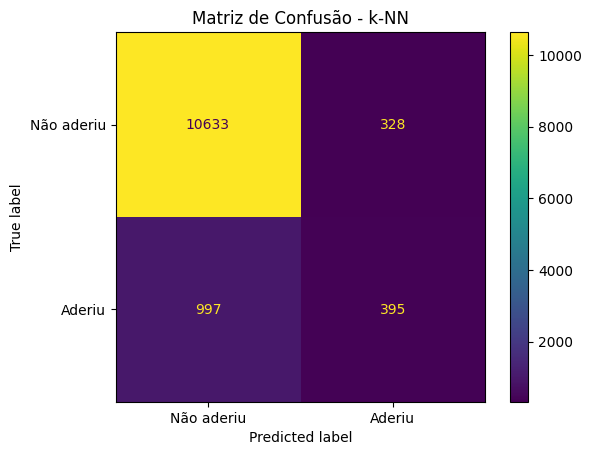

In [ ]:
# Matriz de confusão - k-NN

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=["Não aderiu", "Aderiu"]
)

plt.title("Matriz de Confusão - k-NN")
plt.show()

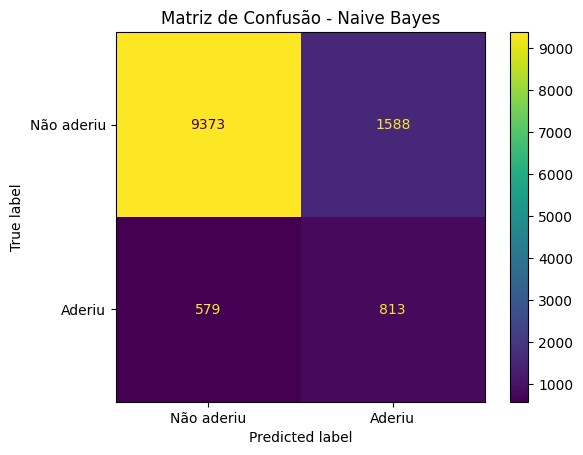

In [ ]:
# Matriz de confusão - Naive Bayes

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    display_labels=["Não aderiu", "Aderiu"]
)

plt.title("Matriz de Confusão - Naive Bayes")
plt.show()

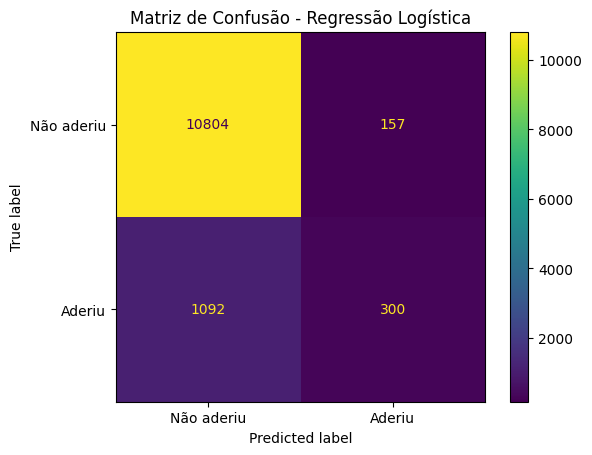

In [ ]:
# Matriz de confusão - Regressão Logística

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistica,
    display_labels=["Não aderiu", "Aderiu"]
)

plt.title("Matriz de Confusão - Regressão Logística")
plt.show()

In [ ]:
# KNN no cenário completo

pipeline_knn_completo = Pipeline([
    ("preprocessamento", preprocessamento_completo),
    ("modelo", KNeighborsClassifier(
        n_neighbors=grid_knn.best_params_["modelo__n_neighbors"]
    ))
])

pipeline_knn_completo.fit(X_train_completo, y_train)

y_pred_knn_completo = pipeline_knn_completo.predict(X_test_completo)

In [ ]:
# Criando o pré-processamento do cenário completo

preprocessamento_completo = ColumnTransformer(
    transformers=[
        (
            "numericas",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            colunas_numericas_completo
        ),
        (
            "categoricas",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            colunas_categoricas_completo
        )
    ]
)

In [ ]:
pipeline_nb_completo = Pipeline([
    ("preprocessamento", preprocessamento_completo),
    ("modelo", GaussianNB())
])

pipeline_nb_completo.fit(X_train_completo, y_train)

y_pred_nb_completo = pipeline_nb_completo.predict(X_test_completo)

print("Naive Bayes do cenário completo treinado com sucesso!")
print("Previsões realizadas:", len(y_pred_nb_completo))

Naive Bayes do cenário completo treinado com sucesso!
Previsões realizadas: 12353


In [ ]:
# Consolidando os resultados dos dois cenários

resultados_completo = []

resultados_completo.append(
    calcular_metricas(
        y_test,
        y_pred_knn_completo,
        "k-NN",
        "Completo"
    )
)

resultados_completo.append(
    calcular_metricas(
        y_test,
        y_pred_nb_completo,
        "Naive Bayes",
        "Completo"
    )
)

resultados_completo.append(
    calcular_metricas(
        y_test,
        y_pred_logistica_completo,
        "Regressão Logística",
        "Completo"
    )
)

tabela_completo = pd.DataFrame(resultados_completo)

tabela_final = pd.concat(
    [tabela_principal, tabela_completo],
    ignore_index=True
)

tabela_final

,Cenário,Modelo,Acurácia,Precisão,Recall,F1
0,Principal,k-NN,0.892739,0.546335,0.283764,0.373522
1,Principal,Naive Bayes,0.824577,0.338609,0.584052,0.428684
2,Principal,Regressão Logística,0.898891,0.656455,0.215517,0.324500
3,Completo,k-NN,0.898000,0.568041,0.395833,0.466554
4,Completo,Naive Bayes,0.835667,0.367304,0.634339,0.465227
5,Completo,Regressão Logística,0.908929,0.648169,0.419540,0.509376


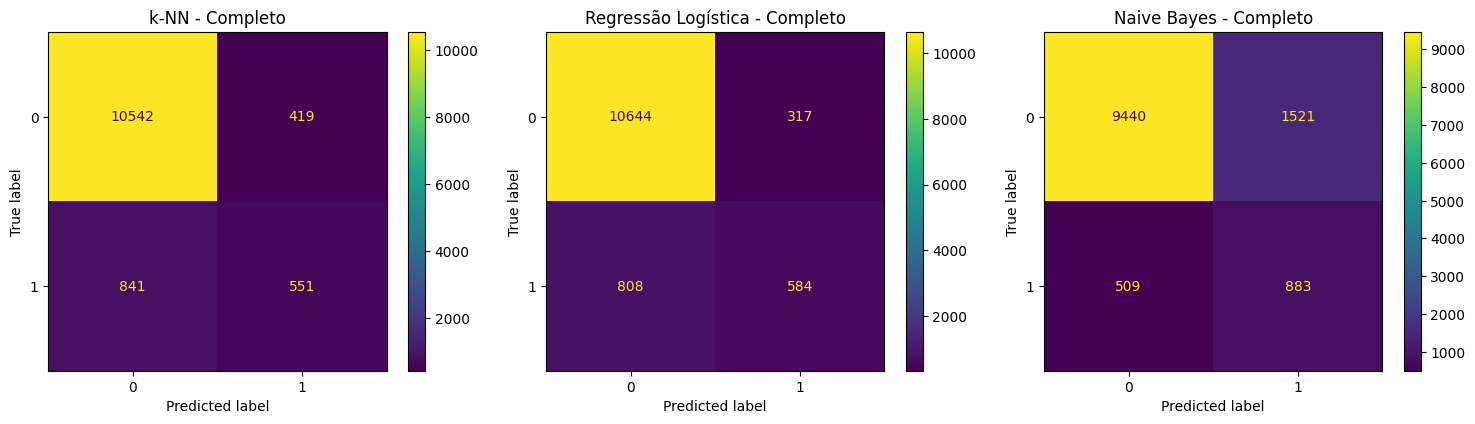

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn_completo,
    ax=axes[0]
)
axes[0].set_title("k-NN - Completo")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistica_completo,
    ax=axes[1]
)
axes[1].set_title("Regressão Logística - Completo")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb_completo,
    ax=axes[2]
)
axes[2].set_title("Naive Bayes - Completo")

plt.tight_layout()
plt.show()

In [ ]:
# Validação cruzada de 5 folds no cenário principal

modelos_cv = {
    "k-NN": grid_knn.best_estimator_,
    "Regressão Logística": grid_logistica.best_estimator_,
    "Naive Bayes": pipeline_nb
}

resultados_cv = []

for nome, modelo in modelos_cv.items():

    scores = cross_val_score(
        modelo,
        X_train_principal,
        y_train,
        cv=cv,
        scoring="f1"
    )

    resultados_cv.append({
        "Modelo": nome,
        "F1 médio": scores.mean(),
        "Desvio padrão": scores.std()
    })

df_cv = pd.DataFrame(resultados_cv)

print("Resultados da validação cruzada:")
print(df_cv)

Resultados da validação cruzada:
                Modelo  F1 médio  Desvio padrão
0                 k-NN  0.379250       0.020630
1  Regressão Logística  0.345041       0.018255
2          Naive Bayes  0.409963       0.011090


In [ ]:
# Previsões dos modelos no cenário principal

y_pred_knn_principal = grid_knn.predict(X_test_principal)

y_pred_logistica_principal = grid_logistica.predict(X_test_principal)

y_pred_nb_principal = pipeline_nb.predict(X_test_principal)

print("Previsões do cenário principal realizadas com sucesso!")
print("k-NN:", len(y_pred_knn_principal))
print("Regressão Logística:", len(y_pred_logistica_principal))
print("Naive Bayes:", len(y_pred_nb_principal))

Previsões do cenário principal realizadas com sucesso!
k-NN: 12353
Regressão Logística: 12353
Naive Bayes: 12353


In [ ]:
# Criando os resultados dos dois cenários

# Resultados do cenário principal
resultados_principal = []

resultados_principal.append(
    calcular_metricas(
        y_test,
        y_pred_knn_principal,
        "k-NN",
        "Principal"
    )
)

resultados_principal.append(
    calcular_metricas(
        y_test,
        y_pred_logistica_principal,
        "Regressão Logística",
        "Principal"
    )
)

resultados_principal.append(
    calcular_metricas(
        y_test,
        y_pred_nb_principal,
        "Naive Bayes",
        "Principal"
    )
)

df_resultados_principal = pd.DataFrame(resultados_principal)


# Resultados do cenário completo
resultados_completo = []

resultados_completo.append(
    calcular_metricas(
        y_test,
        y_pred_knn_completo,
        "k-NN",
        "Completo"
    )
)

resultados_completo.append(
    calcular_metricas(
        y_test,
        y_pred_logistica_completo,
        "Regressão Logística",
        "Completo"
    )
)

resultados_completo.append(
    calcular_metricas(
        y_test,
        y_pred_nb_completo,
        "Naive Bayes",
        "Completo"
    )
)

df_resultados_completo = pd.DataFrame(resultados_completo)


# Juntando os dois cenários
df_resultados_final = pd.concat(
    [df_resultados_principal, df_resultados_completo],
    ignore_index=True
)

print("Resultados finais dos modelos:")
display(df_resultados_final)

Resultados finais dos modelos:


,Cenário,Modelo,Acurácia,Precisão,Recall,F1
0,Principal,k-NN,0.892739,0.546335,0.283764,0.373522
1,Principal,Regressão Logística,0.898891,0.656455,0.215517,0.324500
2,Principal,Naive Bayes,0.824577,0.338609,0.584052,0.428684
3,Completo,k-NN,0.898000,0.568041,0.395833,0.466554
4,Completo,Regressão Logística,0.908929,0.648169,0.419540,0.509376
5,Completo,Naive Bayes,0.835667,0.367304,0.634339,0.465227


In [ ]:
# Relatório de classificação - cenário principal

print("=== k-NN - Cenário Principal ===")
print(classification_report(y_test, y_pred_knn_principal))

print("=== Regressão Logística - Cenário Principal ===")
print(classification_report(y_test, y_pred_logistica_principal))

print("=== Naive Bayes - Cenário Principal ===")
print(classification_report(y_test, y_pred_nb_principal))

=== k-NN - Cenário Principal ===
              precision    recall  f1-score   support

           0       0.91      0.97      0.94     10961
           1       0.55      0.28      0.37      1392

    accuracy                           0.89     12353
   macro avg       0.73      0.63      0.66     12353
weighted avg       0.87      0.89      0.88     12353

=== Regressão Logística - Cenário Principal ===
              precision    recall  f1-score   support

           0       0.91      0.99      0.95     10961
           1       0.66      0.22      0.32      1392

    accuracy                           0.90     12353
   macro avg       0.78      0.60      0.63     12353
weighted avg       0.88      0.90      0.88     12353

=== Naive Bayes - Cenário Principal ===
              precision    recall  f1-score   support

           0       0.94      0.86      0.90     10961
           1       0.34      0.58      0.43      1392

    accuracy                           0.82     12353
   macr

In [ ]:
# Relatório de classificação - cenário completo

print("=== k-NN - Cenário Completo ===")
print(classification_report(y_test, y_pred_knn_completo))

print("=== Regressão Logística - Cenário Completo ===")
print(classification_report(y_test, y_pred_logistica_completo))

print("=== Naive Bayes - Cenário Completo ===")
print(classification_report(y_test, y_pred_nb_completo))

=== k-NN - Cenário Completo ===
              precision    recall  f1-score   support

           0       0.93      0.96      0.94     10961
           1       0.57      0.40      0.47      1392

    accuracy                           0.90     12353
   macro avg       0.75      0.68      0.71     12353
weighted avg       0.89      0.90      0.89     12353

=== Regressão Logística - Cenário Completo ===
              precision    recall  f1-score   support

           0       0.93      0.97      0.95     10961
           1       0.65      0.42      0.51      1392

    accuracy                           0.91     12353
   macro avg       0.79      0.70      0.73     12353
weighted avg       0.90      0.91      0.90     12353

=== Naive Bayes - Cenário Completo ===
              precision    recall  f1-score   support

           0       0.95      0.86      0.90     10961
           1       0.37      0.63      0.47      1392

    accuracy                           0.84     12353
   macro a

In [ ]:
# Principais variáveis da Regressão Logística

modelo_logistica = grid_logistica.best_estimator_

nomes_variaveis = (
    modelo_logistica
    .named_steps["preprocessamento"]
    .get_feature_names_out()
)

coeficientes = (
    modelo_logistica
    .named_steps["modelo"]
    .coef_[0]
)

coeficientes_df = pd.DataFrame({
    "Variavel": nomes_variaveis,
    "Coeficiente": coeficientes
})

coeficientes_df["Magnitude"] = (
    coeficientes_df["Coeficiente"].abs()
)

coeficientes_df = coeficientes_df.sort_values(
    "Magnitude",
    ascending=False
)

print("5 variáveis com maior magnitude:")
display(coeficientes_df.head(5))

5 variáveis com maior magnitude:


,Variavel,Coeficiente,Magnitude
4,numericas__taxa_variacao_emprego,-2.313958,2.313958
51,categoricas__mes_mar,1.288264,1.288264
5,numericas__indice_precos_consumidor,1.119582,1.119582
49,categoricas__mes_jun,-0.791551,0.791551
44,categoricas__meio_contato_telefone_fixo,-0.686202,0.686202


In [ ]:
# Variáveis com maiores coeficientes positivos e negativos

print("Maiores coeficientes positivos:")
display(
    coeficientes_df
    .sort_values("Coeficiente", ascending=False)
    .head(5)
)

print("\nMaiores coeficientes negativos:")
display(
    coeficientes_df
    .sort_values("Coeficiente", ascending=True)
    .head(5)
)

Maiores coeficientes positivos:


,Variavel,Coeficiente,Magnitude
51,categoricas__mes_mar,1.288264,1.288264
5,numericas__indice_precos_consumidor,1.119582,1.119582
7,numericas__euribor_3m,0.639714,0.639714
26,categoricas__escolaridade_analfabeto,0.358720,0.358720
47,categoricas__mes_dez,0.311467,0.311467



Maiores coeficientes negativos:


,Variavel,Coeficiente,Magnitude
4,numericas__taxa_variacao_emprego,-2.313958,2.313958
49,categoricas__mes_jun,-0.791551,0.791551
44,categoricas__meio_contato_telefone_fixo,-0.686202,0.686202
52,categoricas__mes_nov,-0.666143,0.666143
60,categoricas__resultado_campanha_anterior_fracasso,-0.599024,0.599024


In [ ]:
# Resultados da validação cruzada

df_cv_final = df_cv.copy()

df_cv_final["F1 médio"] = df_cv_final["F1 médio"].round(4)
df_cv_final["Desvio padrão"] = df_cv_final["Desvio padrão"].round(4)

print("Validação cruzada de 5 folds:")
display(df_cv_final)

Validação cruzada de 5 folds:


,Modelo,F1 médio,Desvio padrão
0,k-NN,0.3793,0.0206
1,Regressão Logística,0.3450,0.0183
2,Naive Bayes,0.4100,0.0111


In [ ]:
# Resumo final dos resultados

print("=== CENÁRIO PRINCIPAL ===")
display(df_resultados_principal)

print("\n=== CENÁRIO COMPLETO ===")
display(df_resultados_completo)

print("\n=== VALIDAÇÃO CRUZADA ===")
display(df_cv_final)

=== CENÁRIO PRINCIPAL ===


,Cenário,Modelo,Acurácia,Precisão,Recall,F1
0,Principal,k-NN,0.892739,0.546335,0.283764,0.373522
1,Principal,Regressão Logística,0.898891,0.656455,0.215517,0.324500
2,Principal,Naive Bayes,0.824577,0.338609,0.584052,0.428684



=== CENÁRIO COMPLETO ===


,Cenário,Modelo,Acurácia,Precisão,Recall,F1
0,Completo,k-NN,0.898000,0.568041,0.395833,0.466554
1,Completo,Regressão Logística,0.908929,0.648169,0.419540,0.509376
2,Completo,Naive Bayes,0.835667,0.367304,0.634339,0.465227



=== VALIDAÇÃO CRUZADA ===


,Modelo,F1 médio,Desvio padrão
0,k-NN,0.3793,0.0206
1,Regressão Logística,0.3450,0.0183
2,Naive Bayes,0.4100,0.0111


## Análise dos resultados

Para analisar os resultados, olhamos principalmente para a classe positiva, que representa os clientes que aderiram ao depósito a prazo. Como a quantidade de clientes em cada classe é bem diferente, não dá para considerar somente a acurácia. Por isso, também usamos o F1-score, que leva em conta a precisão e o recall.

No cenário principal, usando apenas as informações disponíveis antes da ligação, o k-NN apresentou acurácia de 89,27%, precisão de 54,63%, recall de 28,38% e F1-score de 37,35%. A Regressão Logística teve a maior acurácia, com 89,89%, e também a maior precisão, com 65,65%. Porém, apresentou recall de 21,55% e F1-score de 32,45%. Já o Naive Bayes apresentou acurácia de 82,46%, precisão de 33,86%, recall de 58,41% e F1-score de 42,87%.

Com esses resultados, o Naive Bayes teve o maior F1-score no cenário principal. Mesmo tendo uma acurácia e uma precisão menores, ele conseguiu identificar mais clientes da classe positiva, apresentando também o maior recall entre os três modelos.

Na validação cruzada com cinco folds, o k-NN apresentou F1 médio de 37,93%, com desvio padrão de 2,06 pontos percentuais. A Regressão Logística apresentou F1 médio de 34,50%, com desvio padrão de 1,83 pontos percentuais. Já o Naive Bayes teve F1 médio de 41,00%, com desvio padrão de 1,11 ponto percentual. Os resultados foram parecidos com os encontrados no conjunto de teste, com o Naive Bayes apresentando o maior F1 médio.

Para o k-NN, a validação cruzada indicou `k = 5` como a melhor configuração entre os valores testados. Para a Regressão Logística, o valor escolhido para o hiperparâmetro `C` foi 100.

No cenário completo, foi utilizada também a variável `duracao_ligacao_seg`. Nesse caso, os três modelos apresentaram um F1-score maior. O k-NN apresentou 46,66%, a Regressão Logística 50,94% e o Naive Bayes 46,52%. A Regressão Logística também apresentou a maior acurácia nesse cenário, com 90,89%.

Porém, é importante lembrar que a variável `duracao_ligacao_seg` só fica disponível durante a ligação. Isso significa que ela não estaria disponível antes de entrar em contato com o cliente. Por esse motivo, apesar de o cenário completo apresentar resultados melhores, ele não representa exatamente uma situação em que queremos decidir quais clientes devem ser contatados antes da ligação.

No geral, os resultados mostram que os modelos tiveram desempenhos diferentes dependendo da métrica analisada. No cenário principal, o Naive Bayes apresentou o maior F1-score e o maior recall, enquanto a Regressão Logística apresentou a maior precisão e acurácia. Por isso, foi importante analisar mais de uma métrica para entender melhor o desempenho dos modelos.


In [ ]:
# Tabela final de comparação dos modelos

df_resultados_final

,Cenário,Modelo,Acurácia,Precisão,Recall,F1
0,Principal,k-NN,0.892739,0.546335,0.283764,0.373522
1,Principal,Regressão Logística,0.898891,0.656455,0.215517,0.324500
2,Principal,Naive Bayes,0.824577,0.338609,0.584052,0.428684
3,Completo,k-NN,0.898000,0.568041,0.395833,0.466554
4,Completo,Regressão Logística,0.908929,0.648169,0.419540,0.509376
5,Completo,Naive Bayes,0.835667,0.367304,0.634339,0.465227


In [ ]:
# Resultados da validação cruzada no cenário principal

df_cv_final

,Modelo,F1 médio,Desvio padrão
0,k-NN,0.3793,0.0206
1,Regressão Logística,0.3450,0.0183
2,Naive Bayes,0.4100,0.0111


## Conclusão

Neste projeto, conseguimos comparar três modelos de classificação para tentar prever se os clientes iriam aderir ou não ao depósito a prazo: k-NN, Regressão Logística e Naive Bayes. Ao comparar os resultados, foi possível perceber algumas diferenças entre os modelos, principalmente nas métricas de precisão, recall e F1-score.

No cenário principal, usando apenas as informações disponíveis antes da ligação, o Naive Bayes apresentou o maior F1-score no conjunto de teste, com 42,87%, e também o maior recall, com 58,41%. Na validação cruzada com cinco folds, ele também apresentou o maior F1 médio, de 41,00%, mantendo um resultado parecido com o encontrado no teste.

A Regressão Logística apresentou a maior acurácia no cenário principal, com 89,89%, além da maior precisão, de 65,65%. Porém, seu recall foi de 21,55%, mostrando que o modelo identificou uma quantidade menor de clientes que realmente pertenciam à classe positiva. O k-NN apresentou resultados diferentes dependendo da métrica analisada.

No cenário completo, os três modelos tiveram resultados melhores. A Regressão Logística apresentou F1-score de 50,94% e acurácia de 90,89%. Porém, esse cenário utiliza a variável `duracao_ligacao_seg`, que só fica disponível durante a ligação. Por isso, essa informação não estaria disponível antes de decidir quais clientes devem ser contatados.

Com isso, percebemos que não basta olhar somente para o resultado dos modelos. Também é importante considerar quais informações estão disponíveis no momento em que a previsão será feita. Para o objetivo deste trabalho, o cenário principal representa melhor uma situação em que o banco precisa analisar os clientes antes de realizar a ligação.

Por fim, o projeto mostrou a importância de utilizar diferentes métricas para avaliar modelos de classificação, principalmente quando existe uma diferença grande entre as classes. Ao analisar acurácia, precisão, recall, F1-score, matriz de confusão e validação cruzada, conseguimos ter uma visão mais completa dos resultados e das limitações de cada modelo.
